In [1]:
import torch
import torch.nn.functional as F
import iceaggr
from iceaggr.models import FlatTransformerV2
print(iceaggr.__file__)        # should point into your work clone

torch.manual_seed(0)
config = dict(
    max_pulses_per_dom=41, d_model=256, max_doms=128, num_heads=8, num_layers=2,
    hidden_dim=512, head_hidden_dim=128, dropout=0.0, input_mode='none',
    head_type='pid', num_classes=3,
)
model = FlatTransformerV2(config)
model.train()

B = 32
dom_vectors = torch.randn(B, 128, 4 + 3 * 41)       # (32, 128, 127)
padding_mask = torch.ones(B, 128, dtype=torch.bool)
targets = torch.randint(0, 3, (B,))                 # 0 noise, 1 muon, 2 neutrino

out = model(dom_vectors, padding_mask)
print("logits:", out["logits"].shape, "| embedding:", out["embedding"].shape)

opt = torch.optim.AdamW(model.parameters(), lr=1e-3)
for step in range(200):
    loss = F.cross_entropy(model(dom_vectors, padding_mask)["logits"], targets)
    opt.zero_grad()
    loss.backward()
    opt.step()
    if step % 40 == 0:
        print(step, round(loss.item(), 4))

AttributeError: partially initialized module 'torch' from '/groups/icecube/julie/iceaggr/.venv/lib/python3.13/site-packages/torch/__init__.py' has no attribute '_subclasses' (most likely due to a circular import)

KeyboardInterrupt: 

In [ ]:
import torch
from iceaggr.models.pid_metrics import confusion_matrix, metrics_from_confusion

targets = torch.tensor([0, 0, 1, 1, 2, 2])
logits = torch.tensor([[2., 0, 0], [0, 1., 0], [0, 3., 0], [0, 2., 0], [0, 0, 1.], [0, 0, 5.]])

cm = confusion_matrix(logits, targets)
print(cm)
print(metrics_from_confusion(cm))

tensor([[1, 1, 0],
        [0, 2, 0],
        [0, 0, 2]])
{'accuracy': 0.8333333333333334, 'per_class_accuracy': [0.5, 1.0, 1.0]}


In [1]:
import sys
sys.path.insert(0, "/lustre/hpc/icecube/julie/iceaggr/scripts")
import train_pid

config = {
    "model": dict(max_pulses_per_dom=41, d_model=256, max_doms=128, num_heads=8, num_layers=2,
                  hidden_dim=512, head_hidden_dim=128, dropout=0.0, input_mode="none", num_classes=3),
    "training": dict(lr=1e-4, weight_decay=0.01),
}
model = train_pid.create_model(config, "cpu")
opt, sched = train_pid.build_optimizer_and_scheduler(model, config, total_steps=1000, pct_start=0.1)
print(type(opt).__name__, type(sched).__name__, sched.get_last_lr())

2026-11-11 12:04:11,290 | INFO | PID model: 1,082,119 parameters, 3 classes


AdamW OneCycleLR [4.000000000000002e-06]


In [1]:
import sys, importlib
sys.path.insert(0, "scripts")
import train_pid, fake_pid_data
importlib.reload(train_pid)          # picks up the new function

from iceaggr.data import GeometryLoader

fake_pid_data.write_fake_geometry("/tmp/fake_geometry.csv")
geometry = GeometryLoader("/tmp/fake_geometry.csv")

config = {
    "model": dict(max_pulses_per_dom=41, d_model=256, max_doms=128, num_heads=8, num_layers=2,
                  hidden_dim=512, head_hidden_dim=128, dropout=0.0, input_mode="none", num_classes=3),
    "training": dict(lr=1e-4, weight_decay=0.01, batch_size=64),
    "data": dict(num_workers=0),
}
dataset = fake_pid_data.FakePIDDataset(n_events=1000)
loader = train_pid.create_dataloader(dataset, geometry, config, shuffle=True)
batch = next(iter(loader))
print("dom_vectors:", batch["dom_vectors"].shape)
print("padding_mask:", batch["padding_mask"].shape)
print("targets:", batch["targets"].shape, batch["targets"].dtype)
print("event_ids:", batch["event_ids"].shape)

model = train_pid.create_model(config, "cpu")
out = model(batch["dom_vectors"], batch["padding_mask"])
print("logits:", out["logits"].shape)

2026-11-12 08:56:53,134 | INFO | PID model: 1,082,119 parameters, 3 classes


dom_vectors: torch.Size([64, 128, 127])
padding_mask: torch.Size([64, 128])
targets: torch.Size([64]) torch.int64
event_ids: torch.Size([64])
logits: torch.Size([64, 3])


In [1]:
import sys, importlib
sys.path.insert(0, "scripts")
import train_pid, fake_pid_data
importlib.reload(train_pid)
from iceaggr.data import GeometryLoader

fake_pid_data.write_fake_geometry("/tmp/fake_geometry.csv")
geometry = GeometryLoader("/tmp/fake_geometry.csv")

config = {
    "model": dict(max_pulses_per_dom=41, d_model=256, max_doms=128, num_heads=8, num_layers=2,
                  hidden_dim=512, head_hidden_dim=128, dropout=0.0, input_mode="none", num_classes=3),
    "training": dict(lr=1e-3, weight_decay=0.01, batch_size=64, gradient_clip=1.0, log_every=8),
    "data": dict(num_workers=0),
}
epochs = 10
dataset = fake_pid_data.FakePIDDataset(n_events=1024)           # 16 batches of 64
loader = train_pid.create_dataloader(dataset, geometry, config, shuffle=True)
model = train_pid.create_model(config, "cpu")
total_steps = len(loader) * epochs
opt, sched = train_pid.build_optimizer_and_scheduler(model, config, total_steps, pct_start=0.1)

for epoch in range(1, epochs + 1):
    loss, acc = train_pid.train_epoch(model, loader, opt, sched, "cpu", epoch, config)
    print(f"--> epoch {epoch}: loss {loss:.4f}, accuracy {acc:.3f}")

2026-11-12 09:28:31,885 | INFO | PID model: 1,082,119 parameters, 3 classes
2026-11-12 09:28:34,128 | INFO | Epoch   1 | batch 8/16 | loss 1.0526 | acc 0.426 | 1s
2026-11-12 09:28:35,201 | INFO | Epoch   1 | batch 16/16 | loss 0.8981 | acc 0.532 | 2s


--> epoch 1: loss 0.8981, accuracy 0.532


2026-11-12 09:28:36,291 | INFO | Epoch   2 | batch 8/16 | loss 0.3769 | acc 0.912 | 1s
2026-11-12 09:28:37,357 | INFO | Epoch   2 | batch 16/16 | loss 0.1951 | acc 0.956 | 2s


--> epoch 2: loss 0.1951, accuracy 0.956


2026-11-12 09:28:38,431 | INFO | Epoch   3 | batch 8/16 | loss 0.0006 | acc 1.000 | 1s
2026-11-12 09:28:39,480 | INFO | Epoch   3 | batch 16/16 | loss 0.0003 | acc 1.000 | 2s


--> epoch 3: loss 0.0003, accuracy 1.000


... (10 outputs left out)

2026-11-12 09:28:49,703 | INFO | Epoch   9 | batch 8/16 | loss 0.0000 | acc 1.000 | 1s
2026-11-12 09:28:50,574 | INFO | Epoch   9 | batch 16/16 | loss 0.0000 | acc 1.000 | 2s


--> epoch 9: loss 0.0000, accuracy 1.000


2026-11-12 09:28:51,470 | INFO | Epoch  10 | batch 8/16 | loss 0.0000 | acc 1.000 | 1s
2026-11-12 09:28:52,353 | INFO | Epoch  10 | batch 16/16 | loss 0.0000 | acc 1.000 | 2s


--> epoch 10: loss 0.0000, accuracy 1.000


In [1]:
import sys, importlib
sys.path.insert(0, "scripts")
import train_pid, fake_pid_data
importlib.reload(train_pid)
from iceaggr.data import GeometryLoader

fake_pid_data.write_fake_geometry("/tmp/fake_geometry.csv")
geometry = GeometryLoader("/tmp/fake_geometry.csv")

config = {
    "model": dict(max_pulses_per_dom=41, d_model=256, max_doms=128, num_heads=8, num_layers=2,
                  hidden_dim=512, head_hidden_dim=128, dropout=0.0, input_mode="none", num_classes=3),
    "training": dict(lr=1e-3, weight_decay=0.01, batch_size=64, gradient_clip=1.0, log_every=8),
    "data": dict(num_workers=0),
}

val_ds = fake_pid_data.FakePIDDataset(n_events=512, seed=1)
val_loader = train_pid.create_dataloader(val_ds, geometry, config, shuffle=False)
model = train_pid.create_model(config, "cpu")

m0 = train_pid.validate(model, val_loader, "cpu", config)
print("untrained:", train_pid.format_metrics(m0))

train_ds = fake_pid_data.FakePIDDataset(n_events=1024, seed=0)
train_loader = train_pid.create_dataloader(train_ds, geometry, config, shuffle=True)
epochs = 4
opt, sched = train_pid.build_optimizer_and_scheduler(model, config, len(train_loader) * epochs, pct_start=0.1)
for epoch in range(1, epochs + 1):
    train_pid.train_epoch(model, train_loader, opt, sched, "cpu", epoch, config)

m1 = train_pid.validate(model, val_loader, "cpu", config)
print("trained:  ", train_pid.format_metrics(m1))
print(m1["confusion_matrix"])

2026-11-12 10:20:32,181 | INFO | PID model: 1,082,119 parameters, 3 classes


untrained: loss 1.0990 | acc 0.354 | per class: noise 0.000, muon 0.000, neutrino 1.000


2026-11-12 10:20:35,010 | INFO | Epoch   1 | batch 8/16 | loss 1.1227 | acc 0.443 | 1s
2026-11-12 10:20:35,972 | INFO | Epoch   1 | batch 16/16 | loss 0.9621 | acc 0.529 | 2s
2026-11-12 10:20:36,968 | INFO | Epoch   2 | batch 8/16 | loss 0.4089 | acc 0.883 | 1s
2026-11-12 10:20:37,939 | INFO | Epoch   2 | batch 16/16 | loss 0.2150 | acc 0.941 | 2s
2026-11-12 10:20:38,910 | INFO | Epoch   3 | batch 8/16 | loss 0.0031 | acc 1.000 | 1s
2026-11-12 10:20:39,885 | INFO | Epoch   3 | batch 16/16 | loss 0.0023 | acc 1.000 | 2s
2026-11-12 10:20:40,844 | INFO | Epoch   4 | batch 8/16 | loss 0.0011 | acc 1.000 | 1s
2026-11-12 10:20:41,820 | INFO | Epoch   4 | batch 16/16 | loss 0.0011 | acc 1.000 | 2s


trained:   loss 0.0010 | acc 1.000 | per class: noise 1.000, muon 1.000, neutrino 1.000
tensor([[164,   0,   0],
        [  0, 167,   0],
        [  0,   0, 181]])


(<Figure size 500x450 with 2 Axes>,
 <Axes: xlabel='predicted class', ylabel='true class'>)

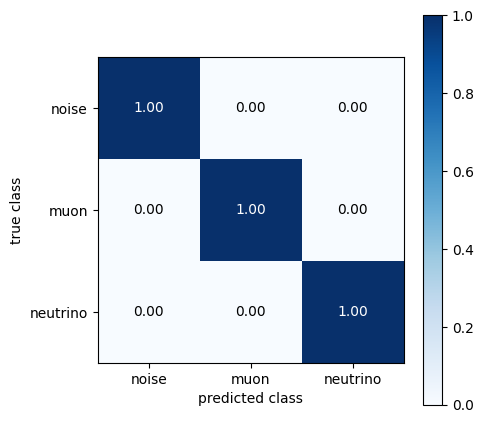

In [2]:
from iceaggr.models.pid_metrics import CLASS_NAMES, plot_confusion_matrix

plot_confusion_matrix(m1["confusion_matrix"], CLASS_NAMES, path="/tmp/cm_fake.png")

In [2]:
import pandas as pd
df = pd.read_parquet("predictions/pid_predictions_190470.parquet")
print(df.head())
print(df[["pid_noise_pred", "pid_muon_pred", "pid_neutrino_pred"]].sum(axis=1).describe()[["min", "max"]])

   event_no  pid_noise_pred  pid_muon_pred  pid_neutrino_pred  pred_class  \
0         0        0.000009       0.999976           0.000015           1   
1         1        0.000009       0.999976           0.000015           1   
2         2        0.000006       0.000012           0.999982           2   
3         3        0.000006       0.000012           0.999982           2   
4         4        0.999979       0.000016           0.000005           0   

   true_class  
0           1  
1           1  
2           2  
3           2  
4           0  
min    1.0
max    1.0
dtype: float64
